# Cross-Asset Volatility Forecasting: Comparing GARCH Models Across Equities and Cryptocurrencies

**Objective.** Compare three GARCH family models, GARCH(1,1), EGARCH(1,1) and GJR-GARCH(1,1), for forecasting the daily volatility of six assets: three large cap equities (`AAPL`, `JPM`, `XOM`) and three cryptocurrencies (`BTC-USD`, `ETH-USD`, `SOL-USD`). Volatility measures the size of price swings and is a key input to risk management.

**Research questions**

1. Is volatility more persistent in equities or in cryptocurrencies?
2. Do asymmetric models (EGARCH and GJR-GARCH) outperform standard GARCH, and does this depend on the asset class?
3. Does the model with the best in sample fit (AIC) also give the best out of sample forecasts?

**Approach**

| Stage | Description |
|---|---|
| Data collection | Five years of daily prices for all six assets through one reusable extraction class |
| Storage | One SQLite table per asset, read back to compute daily returns |
| Exploration | Prices, returns, volatility clustering and autocorrelation of returns and squared returns |
| Modelling | Three specifications fitted to each asset on the first 80% of its returns (18 models) |
| Comparison | AIC and BIC, volatility persistence, asymmetry parameters and residual diagnostics |
| Validation | Walk forward, one day ahead forecasts on the last 20%, scored with RMSE and QLIKE |

**Data.** Daily OHLCV data from Yahoo Finance through `yfinance`, with adjusted prices. Returns are daily percentage changes of the closing price. The data is downloaded when the notebook runs, so results change slightly with the download date.

**Requirements.** Internet access for package installation and Yahoo Finance, and no GPU. The walk forward step refits every model at every test day and is the slow part. It can take tens of minutes on the full test window.

**Contents**

1. Setup
2. Data collection
3. Data storage and returns
4. Exploratory data analysis
5. Train/test split
6. GARCH modelling
7. Model comparison and diagnostics
8. Walk forward validation
9. Summary

## Step 1: Setup

In [2]:
# Volatility modelling package that is not preinstalled
%pip install arch

Note: you may need to restart the kernel to use updated packages.


In [3]:
# Confirm the installed arch version
import arch

print(arch.__version__)

8.0.0


In [4]:
# Standard library
import sqlite3

# Data, market data and plotting
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# Volatility models and time series plots
from arch import arch_model
from arch.univariate.base import ARCHModelResult
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Show every column in DataFrame output
pd.set_option("display.max_columns", None)


## Step 2: Data Collection
Daily OHLCV data for the equities and cryptocurrencies is collected through one reusable extraction class, and the structure of every result is checked before the data is used.

`MarketDataAPI` wraps `yfinance` and returns the same clean DataFrame for equities and cryptocurrencies. Both are available through the same Yahoo Finance interface (`AAPL` for a stock, `BTC-USD` for a cryptocurrency), so one class covers both.

In [5]:
class MarketDataAPI:
    """Fetch daily OHLCV data for an equity or cryptocurrency ticker via Yahoo Finance."""

    def get_daily(self, ticker: str, period: str = "5y") -> pd.DataFrame:
        """Get daily OHLCV data for one ticker.

        Args:
            ticker: Ticker symbol, for example "AAPL" (equity) or "BTC-USD" (cryptocurrency).
            period: History length as a yfinance period string, such as "5y", "2y" or "max".

        Returns:
            DataFrame with float columns open, high, low, close and volume, and a
            DatetimeIndex named "date".

        Raises:
            Exception: If no data is returned for the ticker.
        """
        raw = yf.Ticker(ticker).history(period=period, auto_adjust=True)

        if raw.empty:
            raise Exception(f"No data returned for ticker: {ticker}")

        df = raw[["Open", "High", "Low", "Close", "Volume"]].copy()
        df.columns = ["open", "high", "low", "close", "volume"]
        df.index = pd.to_datetime(df.index).tz_localize(None)
        df.index.name = "date"
        df = df.astype(float)

        return df


In [6]:
# Validate the output structure on a one year AAPL sample
api = MarketDataAPI()
df_test = api.get_daily(ticker="AAPL", period="1y")

assert isinstance(df_test, pd.DataFrame)
assert isinstance(df_test.index, pd.DatetimeIndex)
assert df_test.index.name == "date"
assert df_test.columns.to_list() == ["open", "high", "low", "close", "volume"]
assert all(df_test.dtypes == float)

print("df_test shape:", df_test.shape)
df_test.head()


df_test shape: (251, 5)


,open,high,low,close,volume
date,,,,,
2025-09-11,226.044995,229.601848,225.815830,229.183395,50208600.0
2025-09-12,228.376386,233.646910,228.177125,233.208542,55824200.0
2025-09-15,236.127741,237.313364,234.164990,235.828842,42699500.0
2025-09-16,236.307083,240.332222,235.450262,237.273514,63421100.0
2025-09-17,238.090497,239.216343,236.855055,238.110428,46508000.0


In [7]:
# Large cap equities from different sectors: technology (AAPL), financials (JPM), energy (XOM)
equity_tickers = ["AAPL", "JPM", "XOM"]

equity_data = {}
for ticker in equity_tickers:
    equity_data[ticker] = api.get_daily(ticker=ticker, period="5y")
    print(f"{ticker}: {equity_data[ticker].shape}")


AAPL: (1254, 5)
JPM: (1254, 5)
XOM: (1254, 5)


In [8]:
# Three major cryptocurrencies
crypto_tickers = ["BTC-USD", "ETH-USD", "SOL-USD"]

crypto_data = {}
for ticker in crypto_tickers:
    crypto_data[ticker] = api.get_daily(ticker=ticker, period="5y")
    print(f"{ticker}: {crypto_data[ticker].shape}")


BTC-USD: (1826, 5)
ETH-USD: (1826, 5)
SOL-USD: (1826, 5)


In [9]:
# Validate that every asset has the expected structure
all_data = {**equity_data, **crypto_data}

for ticker, df in all_data.items():
    assert isinstance(df, pd.DataFrame)
    assert isinstance(df.index, pd.DatetimeIndex)
    assert df.index.name == "date"
    assert df.columns.to_list() == ["open", "high", "low", "close", "volume"]
    assert all(df.dtypes == float)

print("All", len(all_data), "assets retrieved and validated.")
all_data["BTC-USD"].head()


All 6 assets retrieved and validated.


,open,high,low,close,volume
date,,,,,
2021-09-11,44869.839844,45969.292969,44818.265625,45201.457031,3.449984e+10
2021-09-12,45206.628906,46364.878906,44790.460938,46063.269531,2.788198e+10
2021-09-13,46057.214844,46598.679688,43591.320312,44963.074219,4.096994e+10
2021-09-14,44960.050781,47218.125000,44752.332031,47092.492188,3.865215e+10
2021-09-15,47098.000000,48450.468750,46773.328125,48176.347656,3.048450e+10


## Step 3: Data Storage and Returns
The collected data is stored in a shared SQLite database, one table per asset, so later steps can read it back without calling the API again. Daily returns are then computed from the stored closing prices.

In [10]:
# Database access layer shared by every asset
class SQLRepository:
    """Store and retrieve asset data in a SQLite database.

    Args:
        connection: Open SQLite connection.
    """

    def __init__(self, connection: sqlite3.Connection):
        self.connection = connection

    def insert_table(self, table_name: str, records: pd.DataFrame, if_exists: str = "fail") -> dict:
        """Insert a DataFrame into the database as a table.

        Args:
            table_name: Name of the table to create.
            records: DataFrame to store.
            if_exists: What to do when the table exists: "fail", "replace" or "append".

        Returns:
            Dict with "transaction_successful" (bool) and "records_inserted" (int).
        """
        n_inserted = records.to_sql(
            name=table_name, con=self.connection, if_exists=if_exists
        )
        return {
            "transaction_successful": True,
            "records_inserted": n_inserted,
        }

    def read_table(self, table_name: str, limit: int = None) -> pd.DataFrame:
        """Read a table back from the database.

        Args:
            table_name: Name of the table to read.
            limit: Number of most recent rows to return. None returns all rows.

        Returns:
            DataFrame with a DatetimeIndex named "date" and the columns open, high,
            low, close and volume.
        """
        if limit:
            sql = f'SELECT * FROM "{table_name}" ORDER BY date DESC LIMIT {limit}'
        else:
            sql = f'SELECT * FROM "{table_name}"'

        df = pd.read_sql(sql=sql, con=self.connection, parse_dates=["date"], index_col="date")
        return df

In [11]:
# Connect to the SQLite database and wrap it in the repository
connection = sqlite3.connect(database="volatility.sqlite", check_same_thread=False)
repo = SQLRepository(connection=connection)

assert hasattr(repo, "connection")
assert isinstance(repo.connection, sqlite3.Connection)

print("repo type:", type(repo))

repo type: <class '__main__.SQLRepository'>


In [12]:
# One table per asset, named after its ticker. if_exists="replace" keeps re-runs from duplicating rows
for ticker, df in all_data.items():
    response = repo.insert_table(table_name=ticker, records=df, if_exists="replace")
    print(f"{ticker}: {response}")

AAPL: {'transaction_successful': True, 'records_inserted': 1254}
JPM: {'transaction_successful': True, 'records_inserted': 1254}
XOM: {'transaction_successful': True, 'records_inserted': 1254}
BTC-USD: {'transaction_successful': True, 'records_inserted': 1826}
ETH-USD: {'transaction_successful': True, 'records_inserted': 1826}
SOL-USD: {'transaction_successful': True, 'records_inserted': 1826}


In [13]:
# Verify the last insert response and that a table reads back correctly (newest 500 rows)
assert isinstance(response, dict)
assert sorted(response.keys()) == ["records_inserted", "transaction_successful"]

df_check = repo.read_table(table_name="BTC-USD", limit=500)

assert isinstance(df_check, pd.DataFrame)
assert isinstance(df_check.index, pd.DatetimeIndex)
assert df_check.index.name == "date"
assert df_check.columns.to_list() == ["open", "high", "low", "close", "volume"]
assert df_check.shape[0] == 500

print("df_check shape:", df_check.shape)
df_check.head()

df_check shape: (500, 5)


,open,high,low,close,volume
date,,,,,
2026-09-11,76535.953125,76885.257812,76535.953125,76878.718750,3.004059e+10
2026-09-09,78440.601562,79737.296875,77768.148438,78259.523438,2.919241e+10
2026-09-08,79114.906250,79463.273438,77635.687500,78438.578125,3.468017e+10
2026-09-07,80349.195312,80432.312500,78684.929688,79115.851562,2.341443e+10
2026-09-06,79824.601562,80530.648438,79327.500000,80350.046875,1.939186e+10


In [14]:
def get_returns(repo, table_name):
    """Read a price table and compute daily percentage returns.

    Args:
        repo: Repository used to read the table.
        table_name: Table (ticker) to read.

    Returns:
        Series named "return", in percent, sorted by date with no NaN values.
    """
    df = repo.read_table(table_name=table_name)
    df.sort_index(ascending=True, inplace=True)
    returns = (df["close"].pct_change() * 100).dropna()
    returns.name = "return"
    return returns

In [15]:
# Daily percentage returns for every asset
all_tickers = equity_tickers + crypto_tickers
returns_data = {ticker: get_returns(repo, ticker) for ticker in all_tickers}

for ticker, s in returns_data.items():
    print(f"{ticker}: {s.shape}")

AAPL: (1253,)
JPM: (1253,)
XOM: (1253,)
BTC-USD: (1825,)
ETH-USD: (1825,)
SOL-USD: (1825,)


/tmp/ipykernel_58/3564138795.py:16: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns = (df["close"].pct_change() * 100).dropna()
/tmp/ipykernel_58/3564138795.py:16: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns = (df["close"].pct_change() * 100).dropna()
/tmp/ipykernel_58/3564138795.py:16: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns = (df["close"].pct_change() * 100).dropna()


In [16]:
# Validate the return series
for ticker, s in returns_data.items():
    assert isinstance(s, pd.Series)
    assert s.name == "return"
    assert isinstance(s.index, pd.DatetimeIndex)
    assert all(s.index == s.sort_index(ascending=True).index)
    assert s.isnull().sum() == 0

print("All return series validated.")

All return series validated.


## Step 4: Exploratory Data Analysis
Prices, returns, volatility and the autocorrelation structure that motivates GARCH models.

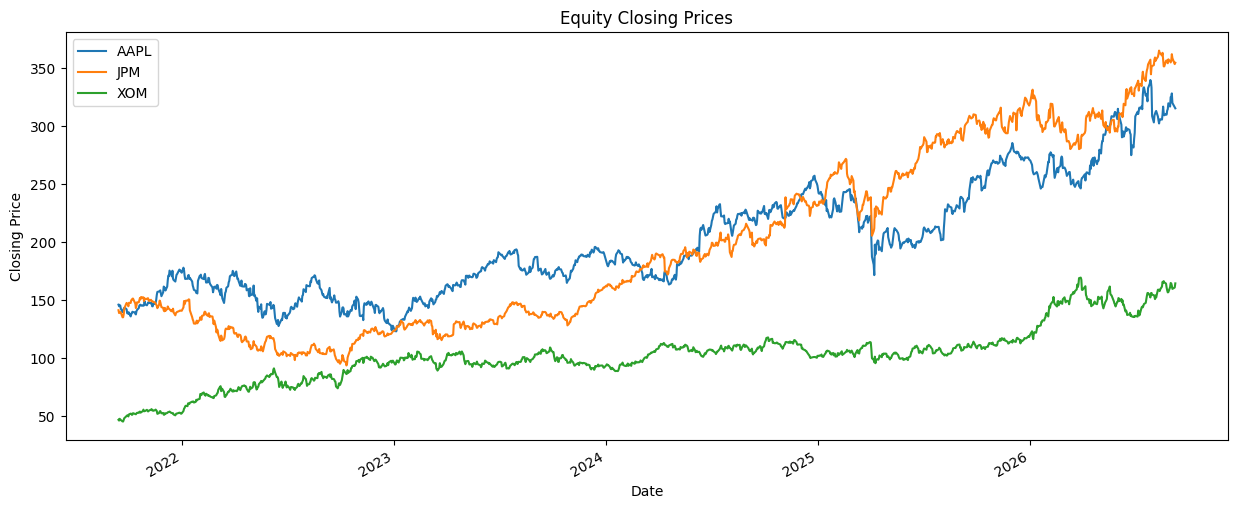

In [17]:
# Closing prices of the equities
fig, ax = plt.subplots(figsize=(15, 6))
for ticker in equity_tickers:
    all_data[ticker]["close"].plot(ax=ax, label=ticker)
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.title("Equity Closing Prices")
plt.legend()

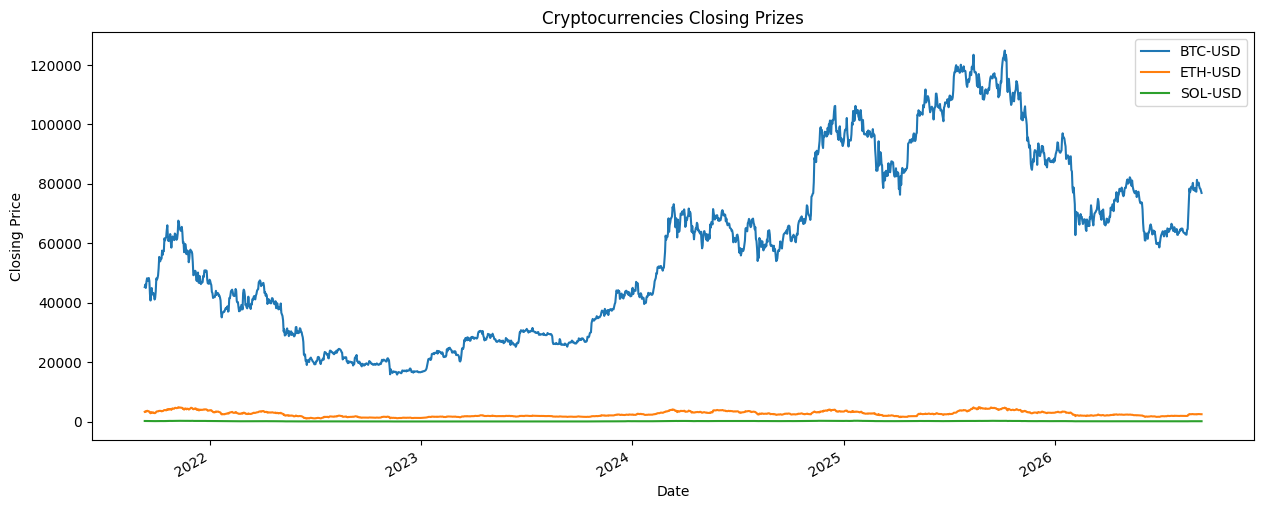

In [18]:
# Closing prices of the cryptocurrencies
fig, ax = plt.subplots(figsize=(15, 6))
for ticker in crypto_tickers:
    all_data[ticker]["close"].plot(ax=ax, label=ticker)
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.title("Cryptocurrencies Closing Prizes")
plt.legend()

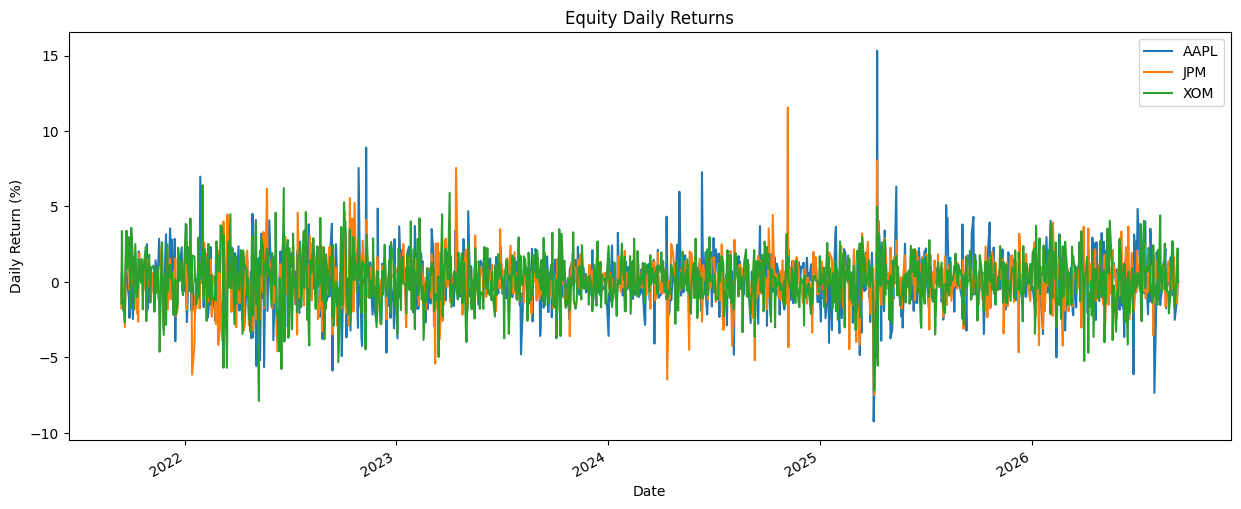

In [19]:
# Daily returns of the equities
fig, ax = plt.subplots(figsize=(15, 6))
for ticker in equity_tickers:
    returns_data[ticker].plot(ax=ax, label=ticker)
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")
plt.title("Equity Daily Returns")
plt.legend()

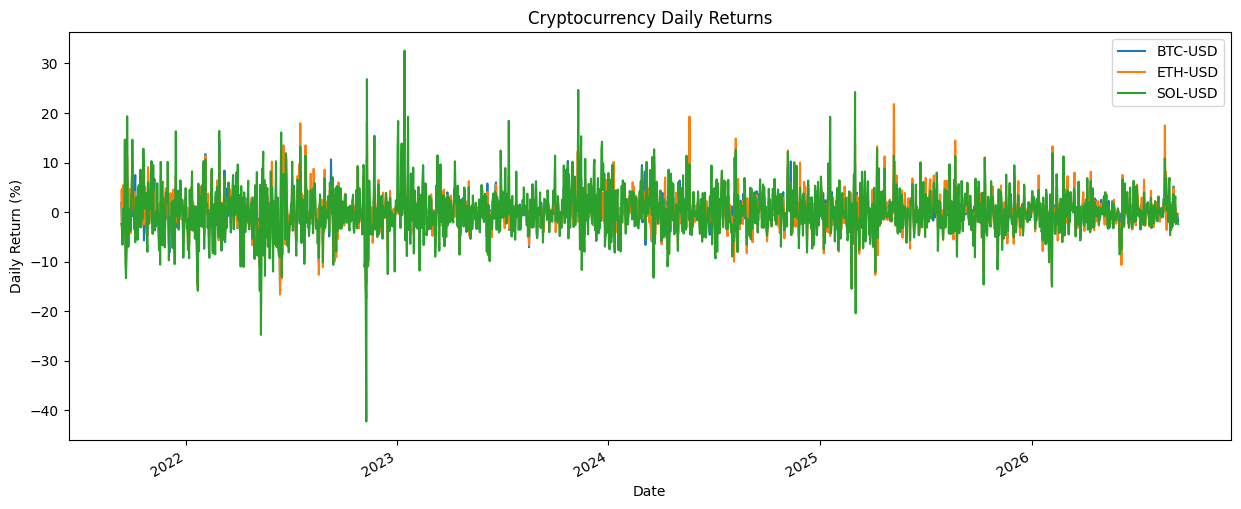

In [20]:
# Daily returns of the cryptocurrencies
fig, ax = plt.subplots(figsize=(15, 6))
for ticker in crypto_tickers:
    returns_data[ticker].plot(ax=ax, label=ticker)
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")
plt.title("Cryptocurrency Daily Returns")
plt.legend()

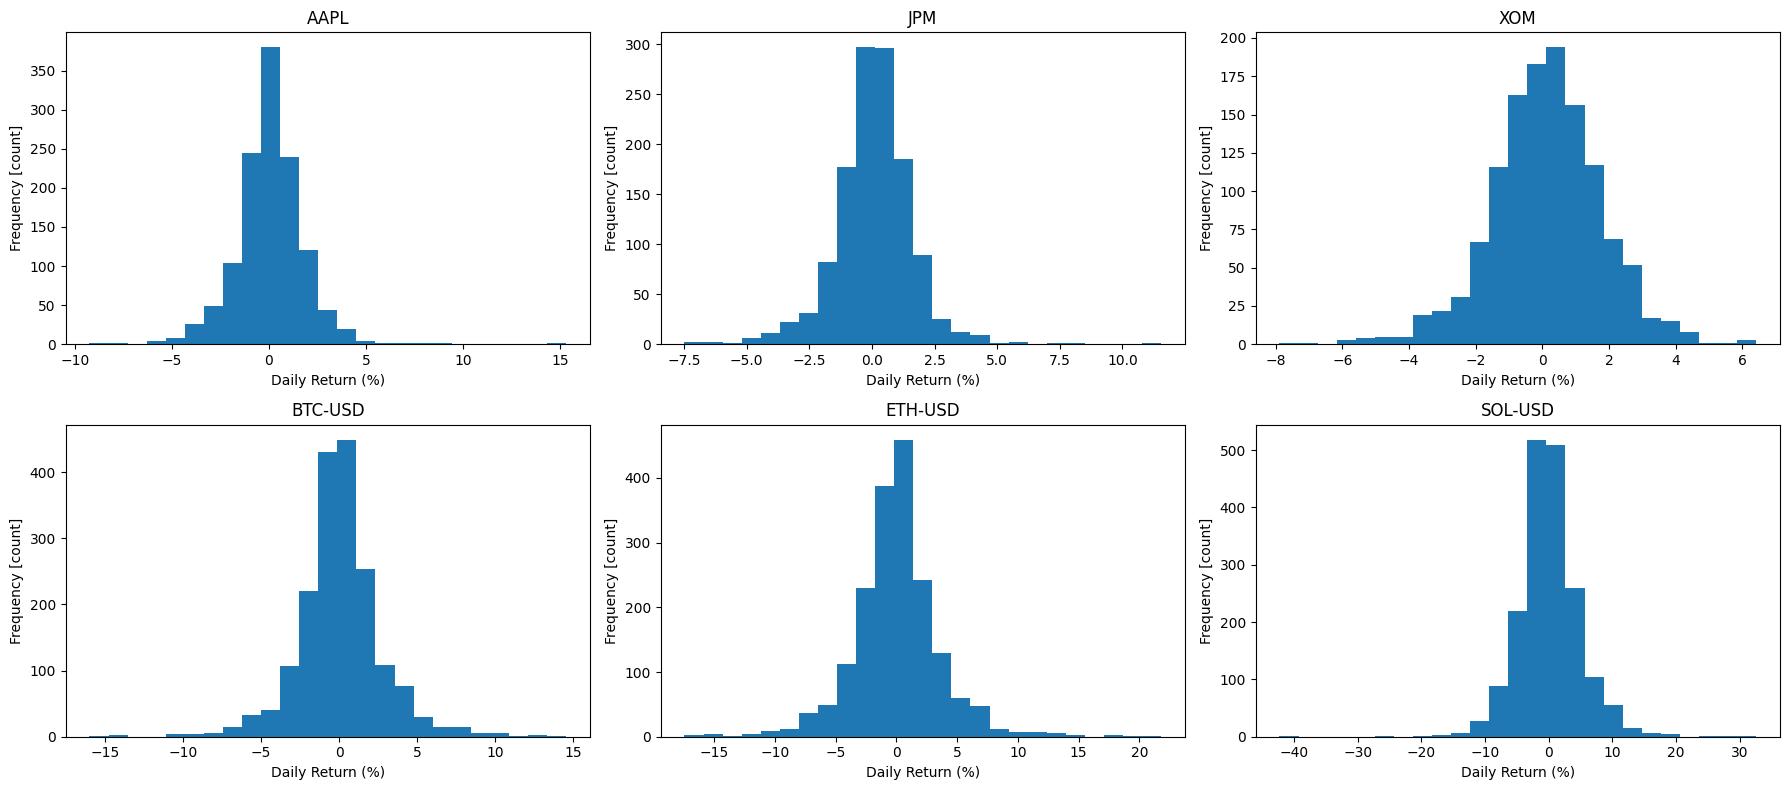

In [21]:
# Return distribution of each asset
fig, axes = plt.subplots(2, 3, figsize=(18, 8))

for ax, ticker in zip(axes.flat, all_tickers):
    ax.hist(returns_data[ticker], bins=25)
    ax.set_title(ticker)
    ax.set_xlabel("Daily Return (%)")
    ax.set_ylabel("Frequency [count]")

plt.tight_layout()

**Volatility.** Daily volatility is the standard deviation of daily returns. Annualised volatility scales it by the square root of 252 trading days, the usual convention for comparing volatility across time horizons. The same 252 day convention is applied to every asset so the figures are comparable. Cryptocurrencies trade every day, so their annualised figures are conservative.

In [22]:
# Daily and annualised volatility per asset
volatility_summary = pd.DataFrame({
    "daily_volatility": {t: returns_data[t].std() for t in all_tickers}
})

volatility_summary["annual_volatility"] = volatility_summary["daily_volatility"] * np.sqrt(252)
volatility_summary["asset_class"] = ["equity"] * len(equity_tickers) + ["crypto"] * len(crypto_tickers)

volatility_summary.sort_values("annual_volatility", ascending=False)

,daily_volatility,annual_volatility,asset_class
SOL-USD,4.936301,78.361352,crypto
ETH-USD,3.637824,57.748673,crypto
BTC-USD,2.711820,43.048803,crypto
AAPL,1.766204,28.037616,equity
XOM,1.679224,26.656861,equity
JPM,1.538376,24.420956,equity


**Volatility clustering.** Squaring the returns removes the sign, so large gains and large losses both register as high volatility. Periods where squared returns bunch together are the pattern GARCH models are designed to capture.

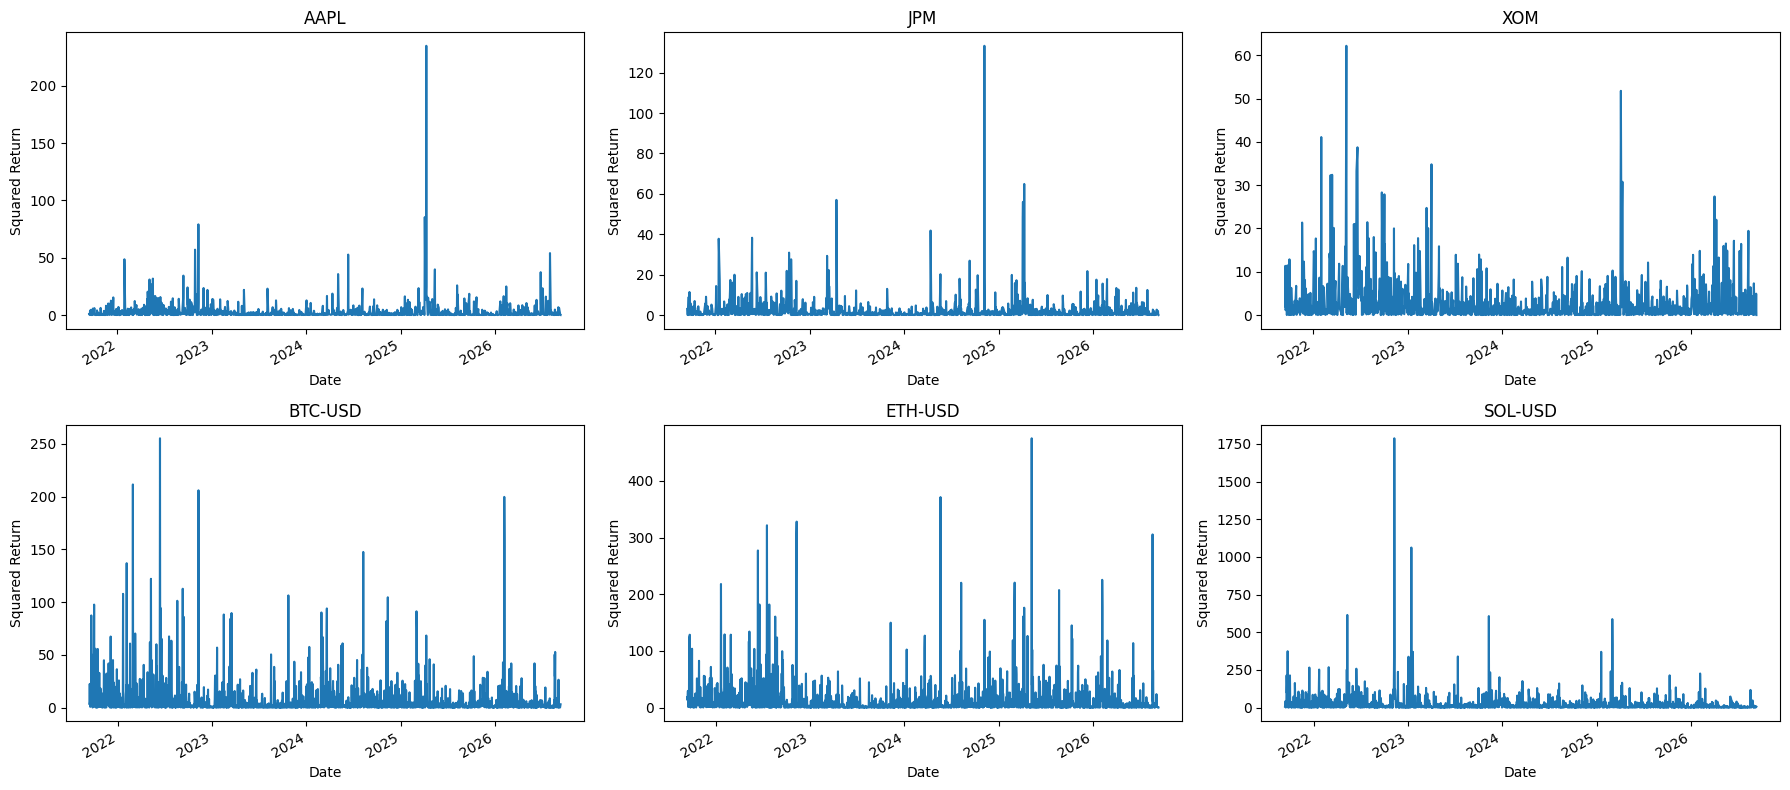

In [23]:
# Squared returns over time
fig, axes = plt.subplots(2, 3, figsize=(18, 8))

for ax, ticker in zip(axes.flat, all_tickers):
    (returns_data[ticker] ** 2).plot(ax=ax)
    ax.set_title(ticker)
    ax.set_xlabel("Date")
    ax.set_ylabel("Squared Return")
    
plt.tight_layout()

**Autocorrelation of returns and squared returns.** Raw returns should show little autocorrelation, since tomorrow's direction is hard to predict from today's. Squared returns should show significant autocorrelation. That gap is the empirical justification for using a GARCH model. The plots are drawn for every asset.

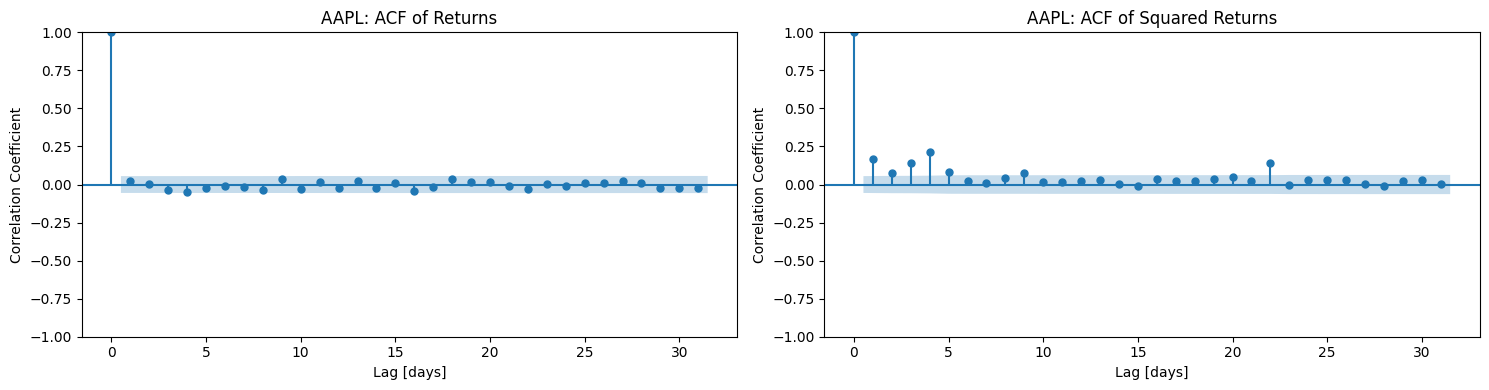

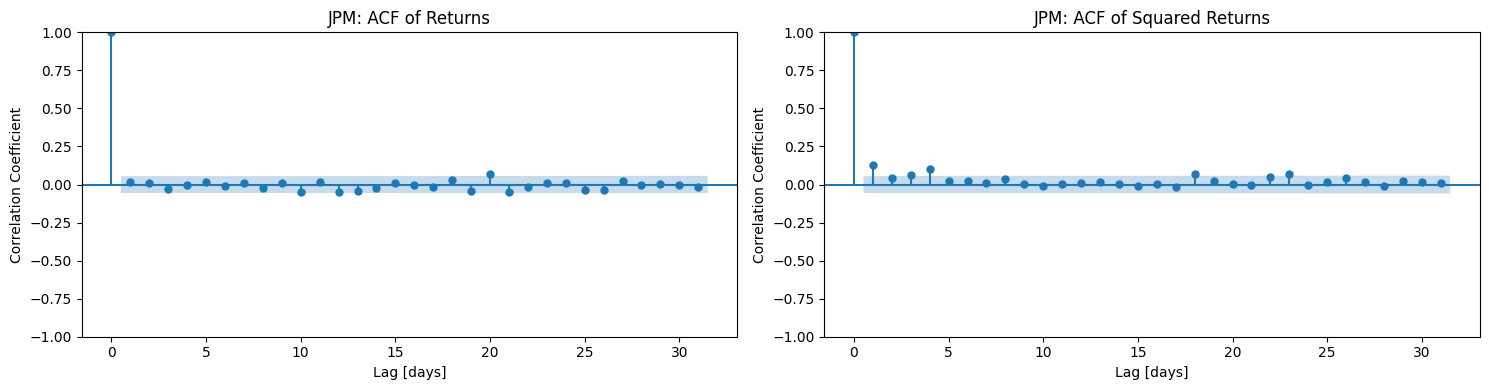

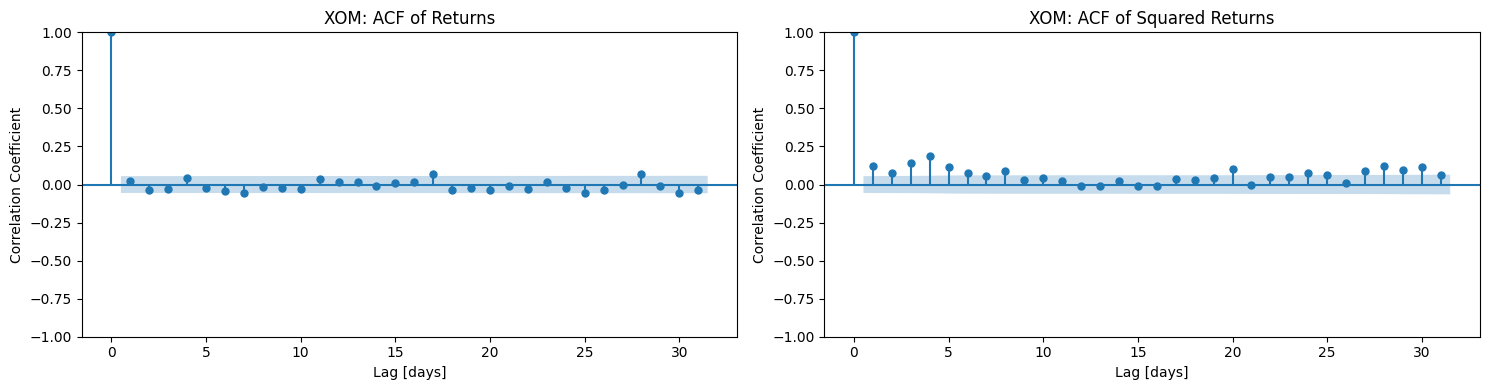

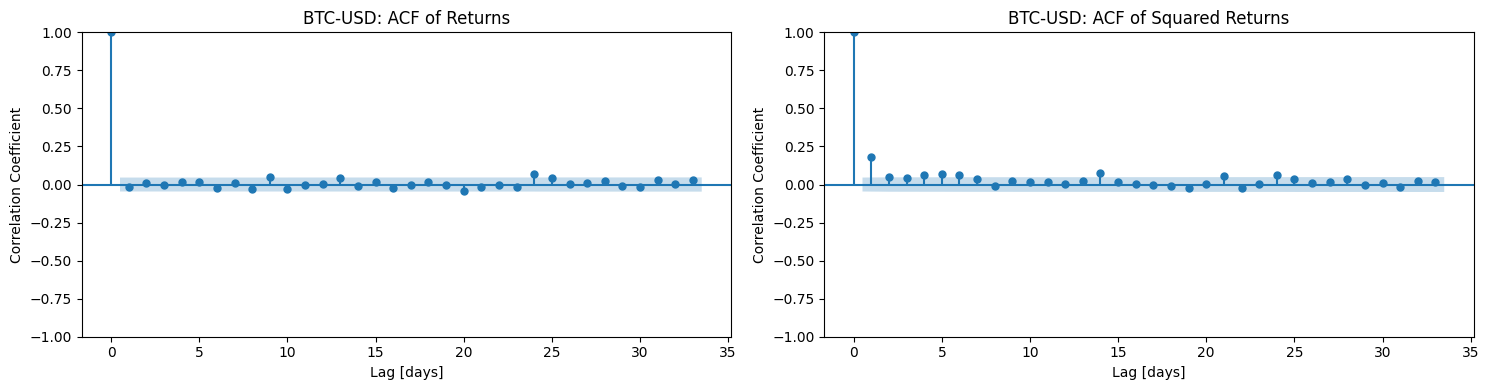

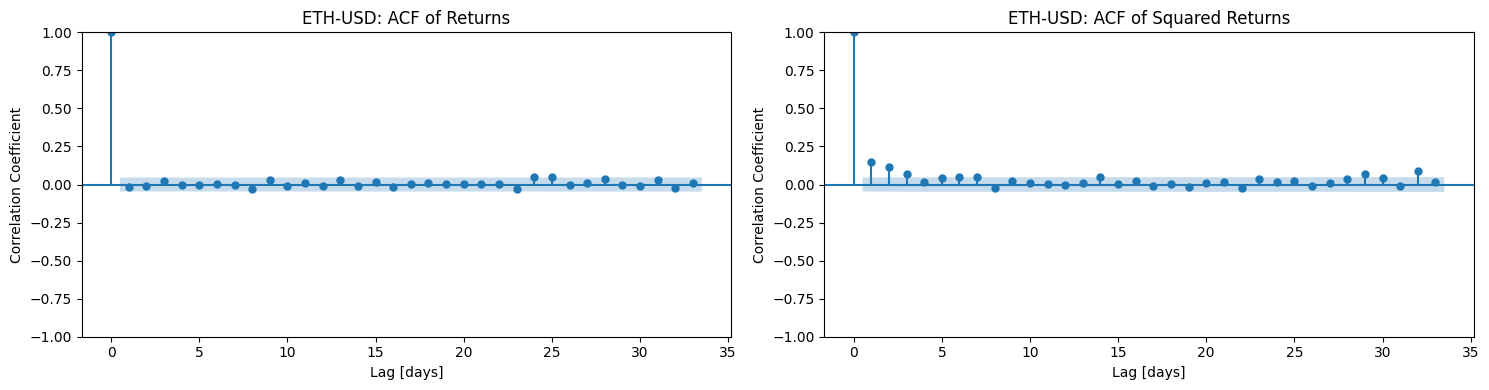

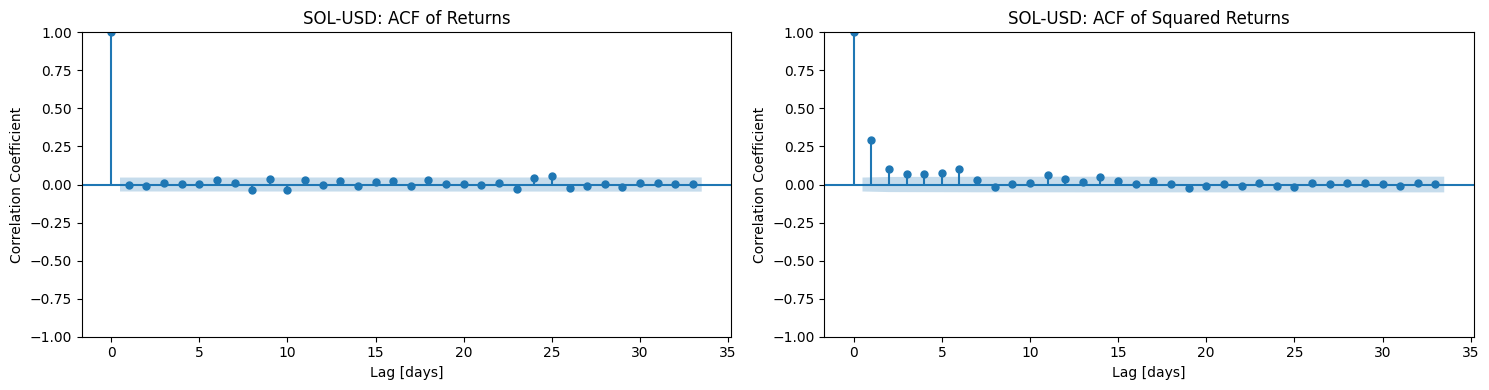

In [24]:
# ACF of returns and of squared returns
for ticker in all_tickers:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4))
    plot_acf(returns_data[ticker], ax=axes[0])
    axes[0].set_title(f"{ticker}: ACF of Returns")
    axes[0].set_xlabel("Lag [days]")
    axes[0].set_ylabel("Correlation Coefficient")

    plot_acf(returns_data[ticker] ** 2, ax=axes[1])
    axes[1].set_title(f"{ticker}: ACF of Squared Returns")
    axes[1].set_xlabel("Lag [days]")
    axes[1].set_ylabel("Correlation Coefficient")

    plt.tight_layout()
    plt.show()

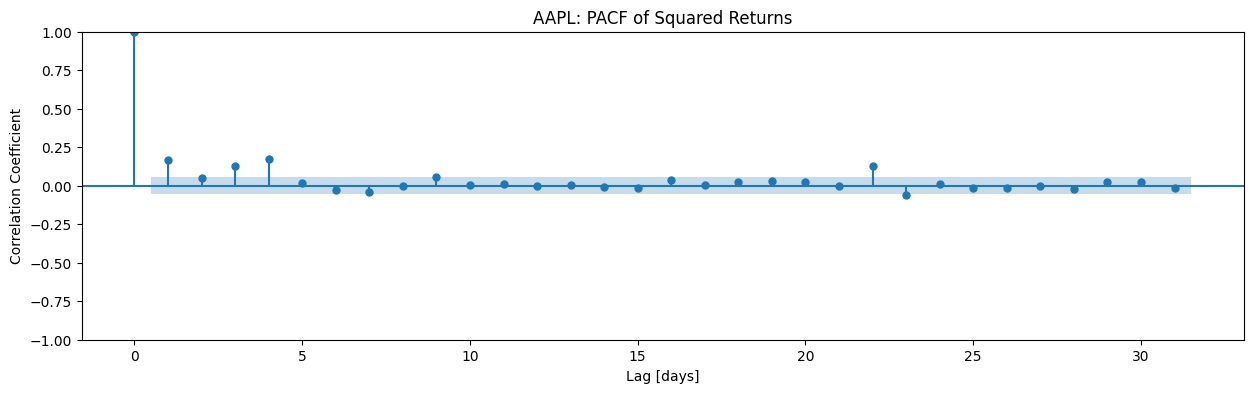

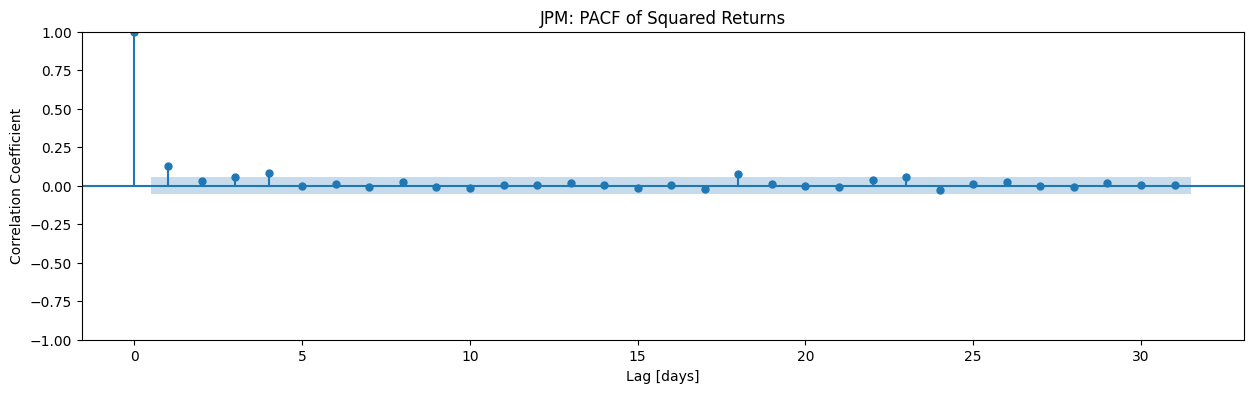

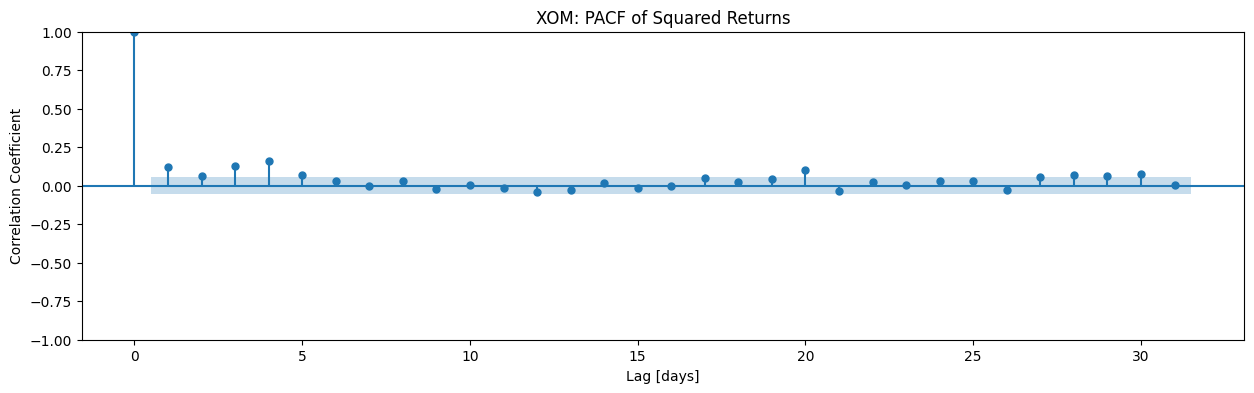

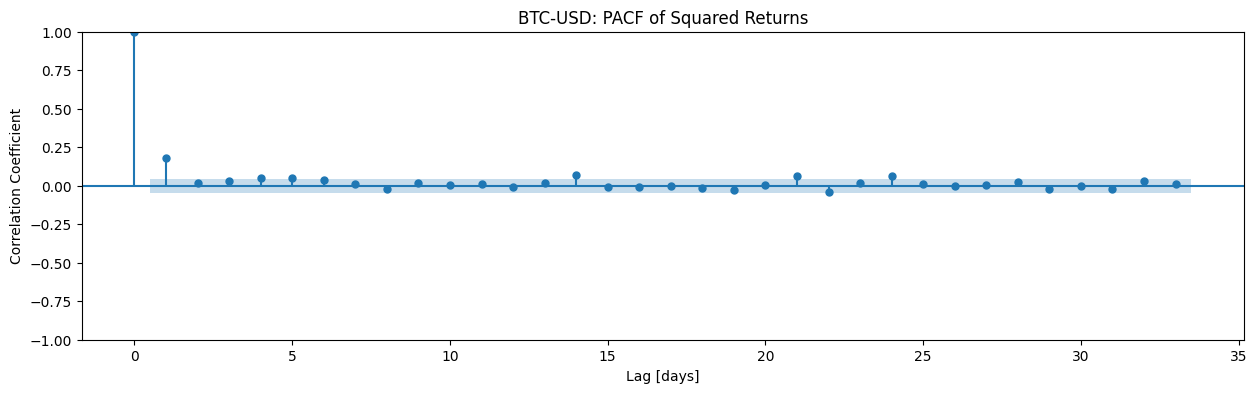

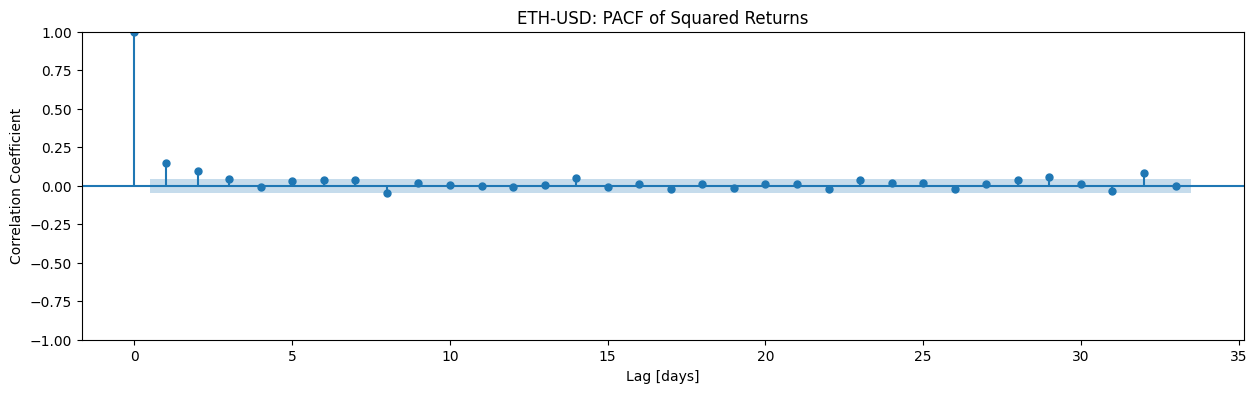

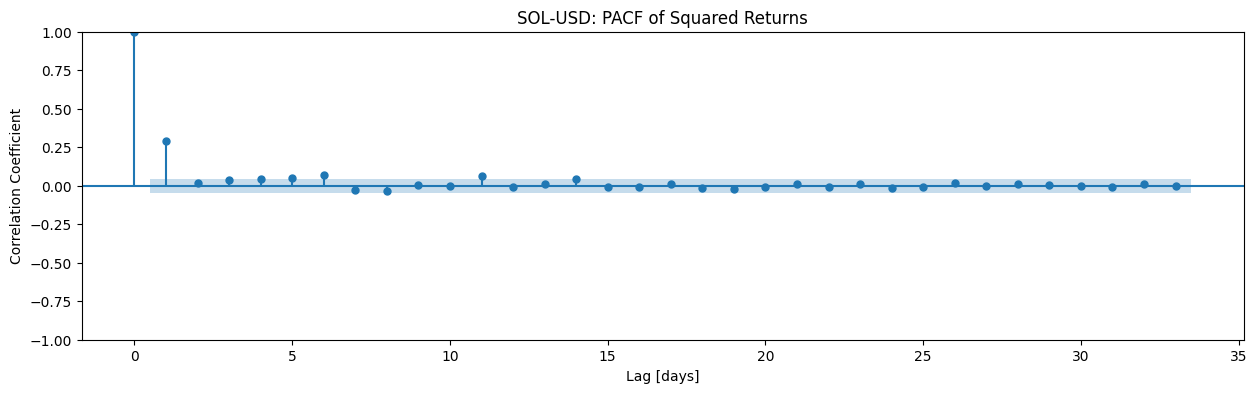

In [25]:
# PACF of squared returns
for ticker in all_tickers:
    fig, ax = plt.subplots(figsize=(15, 4))
    plot_pacf(returns_data[ticker] ** 2, ax=ax)
    ax.set_title(f"{ticker}: PACF of Squared Returns")
    ax.set_xlabel("Lag [days]")
    ax.set_ylabel("Correlation Coefficient")
    plt.show()

## Step 5: Train/Test Split
The first 80% of each asset's returns is used for fitting and the last 20% is held out for walk forward validation. The split is chronological, so no future data reaches the training set.

In [26]:
# Chronological 80/20 split per asset
train_returns = {}
test_returns = {}

for ticker in all_tickers:
    cutoff = int(len(returns_data[ticker]) * 0.8)
    train_returns[ticker] = returns_data[ticker].iloc[:cutoff]
    test_returns[ticker] = returns_data[ticker].iloc[cutoff:]
    print(f"{ticker}: train={train_returns[ticker].shape}, test={test_returns[ticker].shape}")

AAPL: train=(1002,), test=(251,)
JPM: train=(1002,), test=(251,)
XOM: train=(1002,), test=(251,)
BTC-USD: train=(1460,), test=(365,)
ETH-USD: train=(1460,), test=(365,)
SOL-USD: train=(1460,), test=(365,)


## Step 6: GARCH Modelling
A reusable modelling class supports GARCH(1,1), EGARCH(1,1) and GJR-GARCH(1,1). All three specifications are fitted to every asset on its training returns, giving 18 models in total (6 assets and 3 specifications) stored in a nested dictionary.

In [27]:
class GarchModel:
    """Fit and store a GARCH family volatility model for one asset.

    Args:
        ticker: Asset ticker.
        data: Training returns series.
    """
    def __init__(self, ticker: str, data: pd.Series):
        self.ticker = ticker
        self.data = data  # training returns

    def fit(self, p: int=1, q: int=1, vol_model: str = "GARCH") -> ARCHModelResult:
        """Fit a GARCH family model to the training returns.

        Args:
            p: Lag order of the symmetric innovations (the ARCH term in arch's notation).
            q: Lag order of the lagged volatility (the GARCH term in arch's notation).
            vol_model: One of "GARCH", "EGARCH" or "GJR-GARCH".

        Returns:
            The fitted ``ARCHModelResult``, also stored as ``self.model``.

        Raises:
            ValueError: If ``vol_model`` is not recognised.
        """
        if vol_model == "GARCH":
            spec = arch_model(self.data, p=p, q=q, vol="GARCH", rescale=False)
        elif vol_model == "EGARCH":
            spec = arch_model(self.data, p=p, o=1, q=q, vol="EGARCH", rescale=False)
        elif vol_model == "GJR-GARCH":
            spec = arch_model(self.data, o=1, p=p, q=q, vol="GARCH", rescale=False)
        else:
            raise ValueError(f"Unknown vol_model: {vol_model}")

        self.vol_model = vol_model
        self.model = spec.fit(disp=0)
        return self.model

In [28]:
# Check that each specification returns the expected parameters
gm_test = GarchModel(ticker="AAPL", data=train_returns["AAPL"])
gm_test.fit(p=1, q=1, vol_model="GARCH")

assert hasattr(gm_test, "model")
assert isinstance(gm_test.model, ARCHModelResult)
assert gm_test.model.params.index.tolist() == ["mu", "omega", "alpha[1]", "beta[1]"]

print("GARCH params:", gm_test.model.params.index.tolist())

GARCH params: ['mu', 'omega', 'alpha[1]', 'beta[1]']


In [29]:
# EGARCH and GJR-GARCH add an asymmetry (gamma) parameter
gm_test_egarch = GarchModel(ticker="AAPL", data=train_returns["AAPL"])
gm_test_egarch.fit(p=1, q=1, vol_model="EGARCH")

gm_test_gjr = GarchModel(ticker="AAPL", data=train_returns["AAPL"])
gm_test_gjr.fit(p=1, q=1, vol_model="GJR-GARCH")

print("EGARCH params:", gm_test_egarch.model.params.index.tolist())
print("GJR-GARCH params:", gm_test_gjr.model.params.index.tolist())

EGARCH params: ['mu', 'omega', 'alpha[1]', 'gamma[1]', 'beta[1]']
GJR-GARCH params: ['mu', 'omega', 'alpha[1]', 'gamma[1]', 'beta[1]']


In [30]:
# Fit every specification on every asset (18 models)
vol_models = ["GARCH", "EGARCH", "GJR-GARCH"]
fitted_models = {}

for ticker in all_tickers:
    fitted_models[ticker] = {}
    for vol_model in vol_models:
        gm = GarchModel(ticker=ticker, data=train_returns[ticker])
        gm.fit(p=1, q=1, vol_model=vol_model)
        fitted_models[ticker][vol_model] = gm
        print(f"{ticker} - {vol_model}: converged")

AAPL - GARCH: converged
AAPL - EGARCH: converged
AAPL - GJR-GARCH: converged
JPM - GARCH: converged
JPM - EGARCH: converged
JPM - GJR-GARCH: converged
XOM - GARCH: converged
XOM - EGARCH: converged
XOM - GJR-GARCH: converged
BTC-USD - GARCH: converged
BTC-USD - EGARCH: converged
BTC-USD - GJR-GARCH: converged
ETH-USD - GARCH: converged
ETH-USD - EGARCH: converged
ETH-USD - GJR-GARCH: converged
SOL-USD - GARCH: converged
SOL-USD - EGARCH: converged
SOL-USD - GJR-GARCH: converged


In [31]:
# Registry of fitted models: ticker -> specification -> GarchModel
fitted_models

{'AAPL': {'GARCH': <__main__.GarchModel at 0x7b45bc1bed50>,
  'EGARCH': <__main__.GarchModel at 0x7b45bc122270>,
  'GJR-GARCH': <__main__.GarchModel at 0x7b45b9276b40>},
 'JPM': {'GARCH': <__main__.GarchModel at 0x7b45b87e5280>,
  'EGARCH': <__main__.GarchModel at 0x7b45bcbaccb0>,
  'GJR-GARCH': <__main__.GarchModel at 0x7b45b8f05d90>},
 'XOM': {'GARCH': <__main__.GarchModel at 0x7b45bc4993d0>,
  'EGARCH': <__main__.GarchModel at 0x7b45bc1bd100>,
  'GJR-GARCH': <__main__.GarchModel at 0x7b45bc0f7410>},
 'BTC-USD': {'GARCH': <__main__.GarchModel at 0x7b45bc1bc860>,
  'EGARCH': <__main__.GarchModel at 0x7b45b8d64bc0>,
  'GJR-GARCH': <__main__.GarchModel at 0x7b45bc498620>},
 'ETH-USD': {'GARCH': <__main__.GarchModel at 0x7b45b8d662a0>,
  'EGARCH': <__main__.GarchModel at 0x7b45b8d65a00>,
  'GJR-GARCH': <__main__.GarchModel at 0x7b45b8d667b0>},
 'SOL-USD': {'GARCH': <__main__.GarchModel at 0x7b45b8d66bd0>,
  'EGARCH': <__main__.GarchModel at 0x7b45b8d64e00>,
  'GJR-GARCH': <__main__.Garch

In [32]:
# Validate that all 18 models were fitted
assert len(fitted_models) == 6
for ticker in fitted_models:
    assert len(fitted_models[ticker]) == 3
    for vol_model in vol_models:
        assert isinstance(fitted_models[ticker][vol_model].model, ARCHModelResult)

print("All 18 models fitted and validated.")

All 18 models fitted and validated.


In [33]:
# Full output of one fitted model
fitted_models["AAPL"]["EGARCH"].model

                     Constant Mean - EGARCH Model Results                     
Dep. Variable:                 return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                     EGARCH   Log-Likelihood:               -1929.09
Distribution:                  Normal   AIC:                           3868.17
Method:            Maximum Likelihood   BIC:                           3892.72
                                        No. Observations:                 1002
Date:                Fri, Sep 11 2026   Df Residuals:                     1001
Time:                        01:00:10   Df Model:                            1
                                 Mean Model                                
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
mu             0.0472  5.011e-02      0.942      0.346 [-5.10

In [34]:
# Summary table of one fitted model
fitted_models["BTC-USD"]["GJR-GARCH"].model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                   Constant Mean - GJR-GARCH Model Results                    
==============================================================================
Dep. Variable:                 return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                  GJR-GARCH   Log-Likelihood:               -3517.57
Distribution:                  Normal   AIC:                           7045.13
Method:            Maximum Likelihood   BIC:                           7071.56
                                        No. Observations:                 1460
Date:                Fri, Sep 11 2026   Df Residuals:                     1459
Time:                        01:00:11   Df Model:                            1
                                 Mean Model                                
===========================================================================
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
mu             0.1131  6.415e-02      1.764  7.780e-02 [-1.260e-02,  0.239]
                              Volatility Model                             
===========================================================================
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
omega          0.5727      0.358      1.601      0.109    [ -0.128,  1.274]
alpha[1]       0.0508  3.121e-02      1.627      0.104 [-1.039e-02,  0.112]
gamma[1]       0.0862  4.619e-02      1.866  6.206e-02 [-4.348e-03,  0.177]
beta[1]        0.8371  7.497e-02     11.166  5.962e-29    [  0.690,  0.984]
===========================================================================

Covariance estimator: robust
"""

In [35]:
# Parameter estimates of the same model
params = fitted_models["BTC-USD"]["GJR-GARCH"].model.params
params

mu          0.113139
omega       0.572715
alpha[1]    0.050776
gamma[1]    0.086191
beta[1]     0.837095
Name: params, dtype: float64

## Step 7: Model Comparison and Diagnostics
All 18 models are compared on AIC, BIC, persistence and asymmetry. The best specification per asset is then checked with residual diagnostics.

**Volatility persistence** is measured differently for each specification:

- **GARCH:** `alpha[1] + beta[1]`, the standard persistence measure.
- **GJR-GARCH:** `alpha[1] + beta[1] + 0.5 * gamma[1]`. The factor 0.5 reflects that the leverage term applies only to negative shocks, roughly half of all observations under a symmetric shock assumption.
- **EGARCH:** `beta[1]`. The model works on log variance, so `beta[1]` is the direct AR(1) coefficient on lagged log variance.

Because the definitions differ, persistence is best compared within a specification.

In [36]:
def get_persistence(model_result, vol_model):
    """Compute volatility persistence for a fitted GARCH family model.

    The measure depends on the specification: alpha + beta for GARCH,
    alpha + beta + 0.5 * gamma for GJR-GARCH, and beta for EGARCH.

    Args:
        model_result: Fitted ``ARCHModelResult``.
        vol_model: One of "GARCH", "EGARCH" or "GJR-GARCH".

    Returns:
        Persistence value.
    """
    params = model_result.params
    if vol_model == "GARCH":
        return params["alpha[1]"] + params["beta[1]"]
    elif vol_model == "GJR-GARCH":
        return params["alpha[1]"] + params["beta[1]"] + 0.5 * params["gamma[1]"]
    elif vol_model == "EGARCH":
        return params["beta[1]"]

In [37]:
# Comparison table: AIC, BIC, log likelihood and persistence for each asset and specification
rows = []
for ticker in all_tickers:
    asset_class = "equity" if ticker in equity_tickers else "crypto"
    for vol_model in vol_models:
        result = fitted_models[ticker][vol_model].model
        rows.append({
            "ticker": ticker,
            "asset_class": asset_class,
            "vol_model": vol_model,
            "aic": result.aic,
            "bic": result.bic,
            "log_likelihood": result.loglikelihood,
            "persistence": get_persistence(result, vol_model)
        })

comparison_df = pd.DataFrame(rows)
comparison_df.sort_values(["ticker", "aic"])

,ticker,asset_class,vol_model,aic,bic,log_likelihood,persistence
1,AAPL,equity,EGARCH,3868.170299,3892.719066,-1929.085150,0.950659
2,AAPL,equity,GJR-GARCH,3870.405932,3894.954698,-1930.202966,0.962531
0,AAPL,equity,GARCH,3903.284285,3922.923298,-1947.642143,0.965850
10,BTC-USD,crypto,EGARCH,7035.874931,7062.305890,-3512.937466,0.903535
11,BTC-USD,crypto,GJR-GARCH,7045.130665,7071.561624,-3517.565333,0.930967
9,BTC-USD,crypto,GARCH,7057.157213,7078.301980,-3524.578606,0.932126
14,ETH-USD,crypto,GJR-GARCH,7842.515873,7868.946832,-3916.257937,0.991611
13,ETH-USD,crypto,EGARCH,7844.999306,7871.430265,-3917.499653,0.848889
12,ETH-USD,crypto,GARCH,7864.015098,7885.159865,-3928.007549,0.992918
4,JPM,equity,EGARCH,3655.940039,3680.488805,-1822.970019,0.962561


In [38]:
# Validate the comparison table
assert comparison_df.shape == (18, 7)
assert comparison_df["aic"].isnull().sum() == 0
assert comparison_df["bic"].isnull().sum() == 0

print("Comparison table shape:", comparison_df.shape)

Comparison table shape: (18, 7)


In [39]:
# Best specification per asset by AIC (lowest is best)
best_by_aic = comparison_df.loc[comparison_df.groupby("ticker")["aic"].idxmin()]
best_model_lookup = dict(zip(best_by_aic["ticker"], best_by_aic["vol_model"]))
best_by_aic[["ticker", "asset_class", "vol_model", "aic", "persistence"]].sort_values("asset_class")

,ticker,asset_class,vol_model,aic,persistence
10,BTC-USD,crypto,EGARCH,7035.874931,0.903535
14,ETH-USD,crypto,GJR-GARCH,7842.515873,0.991611
15,SOL-USD,crypto,GARCH,8813.265159,0.910099
1,AAPL,equity,EGARCH,3868.170299,0.950659
4,JPM,equity,EGARCH,3655.940039,0.962561
6,XOM,equity,GARCH,3823.681010,0.991242


In [40]:
# Mean persistence by asset class and specification
comparison_df.groupby(["asset_class", "vol_model"])["persistence"].mean().unstack()

vol_model,EGARCH,GARCH,GJR-GARCH
asset_class,,,
crypto,0.881428,0.945048,0.944890
equity,0.967358,0.910626,0.918458


**Asymmetry (leverage) parameter.** `gamma[1]` exists only in EGARCH and GJR-GARCH. In GJR-GARCH, a positive gamma means negative shocks raise volatility more than positive shocks of the same size, the classic leverage effect. In EGARCH the same effect shows up as a negative gamma, because the parameter enters the model differently.

In [41]:
# Asymmetry parameter of the EGARCH and GJR-GARCH models
asym_rows = []
for ticker in all_tickers:
    asset_class = "equity" if ticker in equity_tickers else "crypto"
    for vol_model in ["EGARCH", "GJR-GARCH"]:
        gamma = fitted_models[ticker][vol_model].model.params["gamma[1]"]
        asym_rows.append({
            "ticker": ticker,
            "asset_class": asset_class,
            "vol_model": vol_model,
            "gamma": gamma,
        })

asym_df = pd.DataFrame(asym_rows)
asym_df.sort_values(["vol_model", "asset_class"])

,ticker,asset_class,vol_model,gamma
6,BTC-USD,crypto,EGARCH,-0.061893
8,ETH-USD,crypto,EGARCH,-0.114007
10,SOL-USD,crypto,EGARCH,-0.013255
0,AAPL,equity,EGARCH,-0.124019
2,JPM,equity,EGARCH,-0.101837
4,XOM,equity,EGARCH,0.004027
7,BTC-USD,crypto,GJR-GARCH,0.086191
9,ETH-USD,crypto,GJR-GARCH,0.039200
11,SOL-USD,crypto,GJR-GARCH,0.038844
1,AAPL,equity,GJR-GARCH,0.145198


**Residual diagnostics.** For each asset's best model by AIC, the plots show the standardised residuals over time, their distribution and the ACF of their squares. A well specified model leaves residuals with no remaining structure: a flat ACF, a roughly normal histogram and no visible pattern over time.

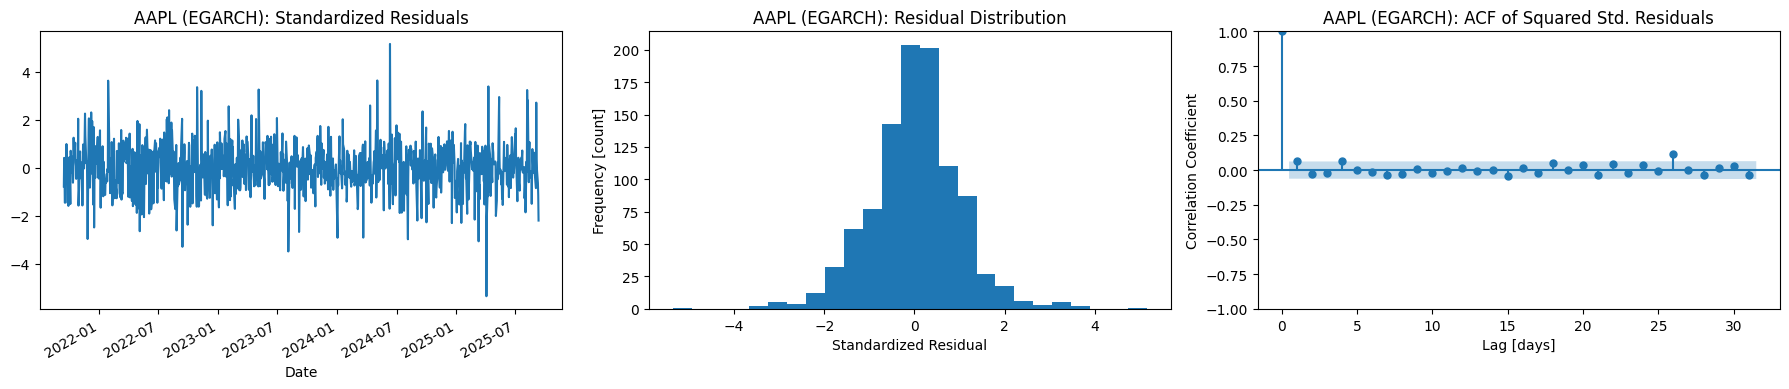

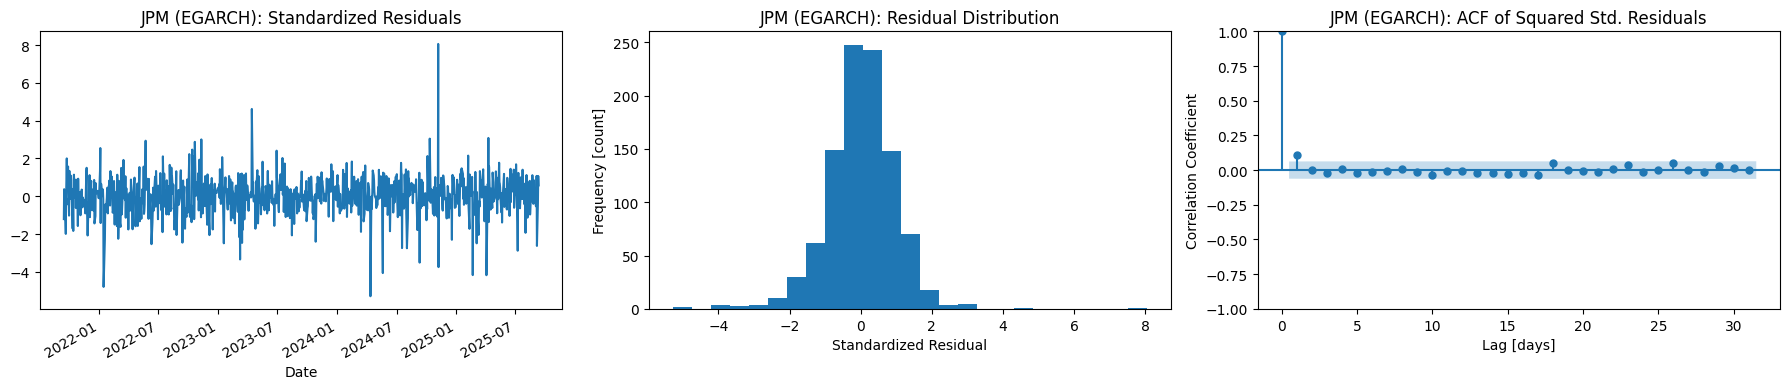

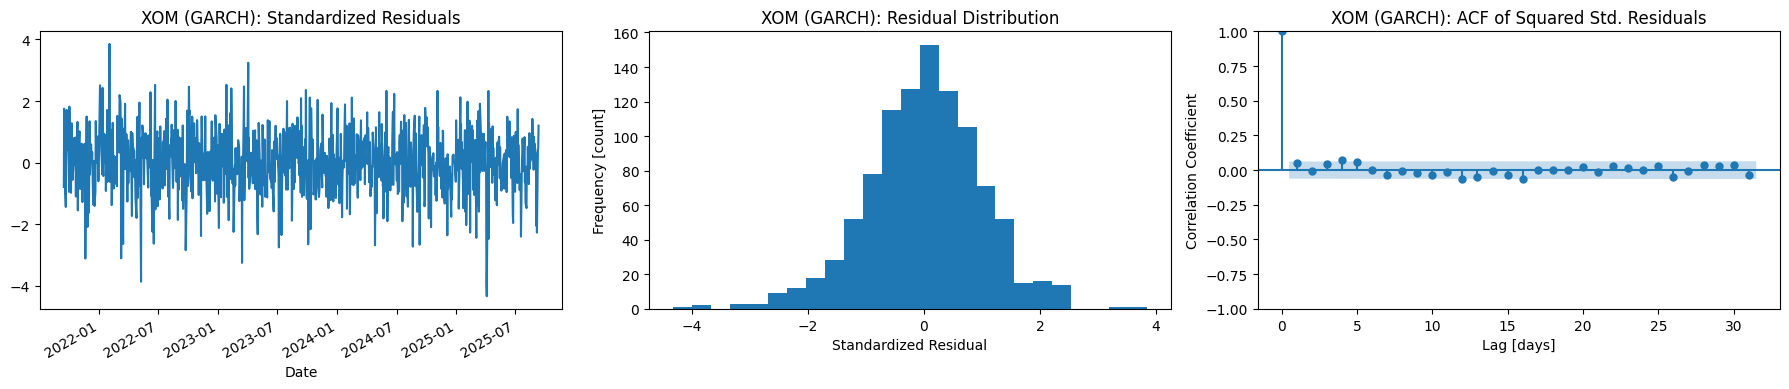

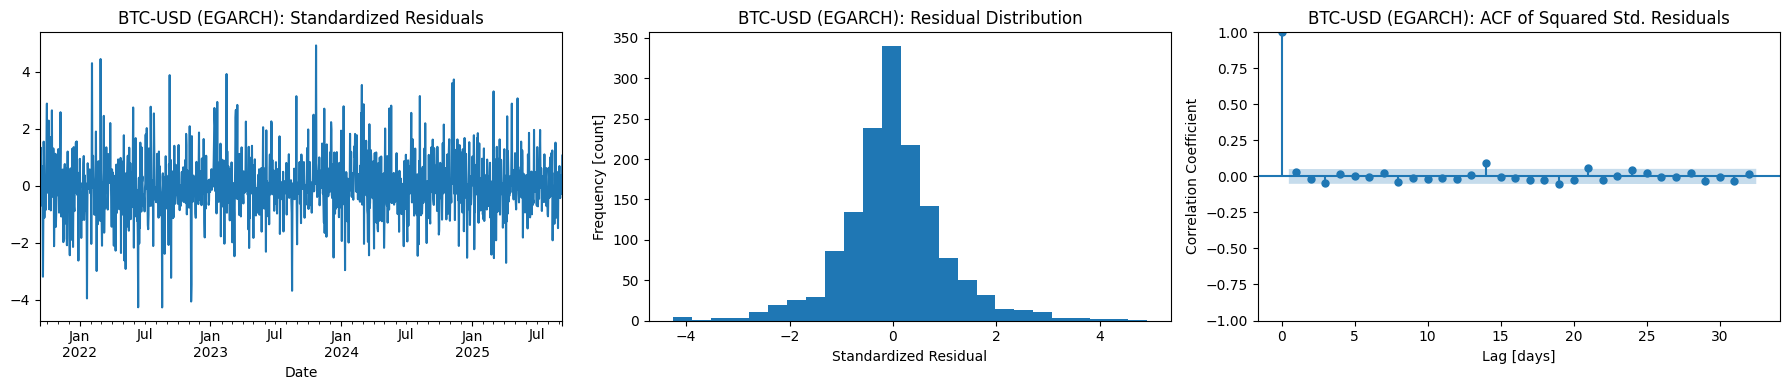

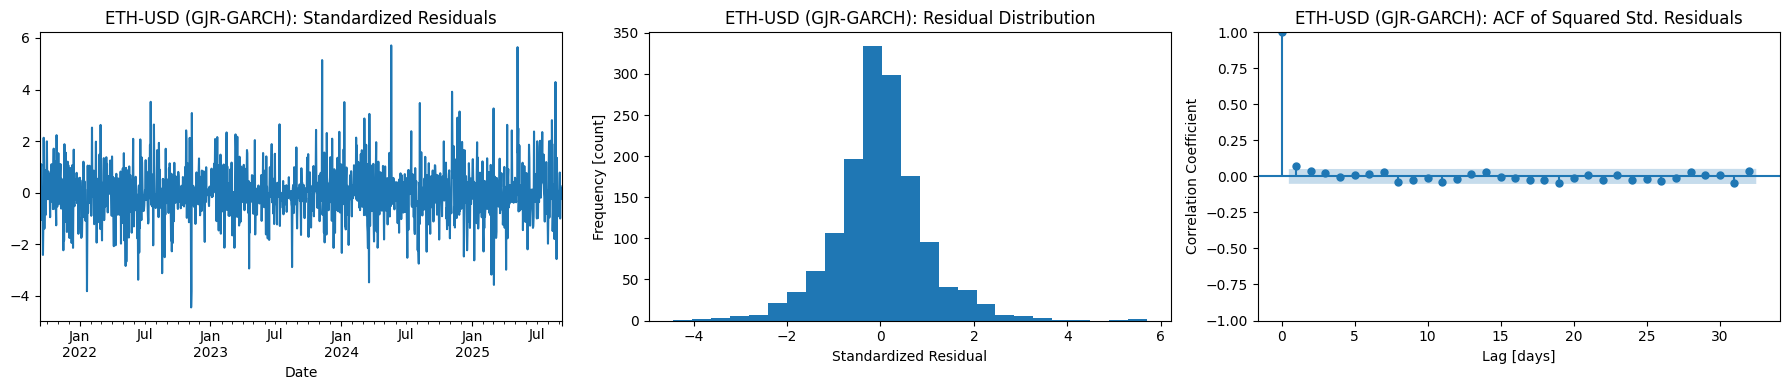

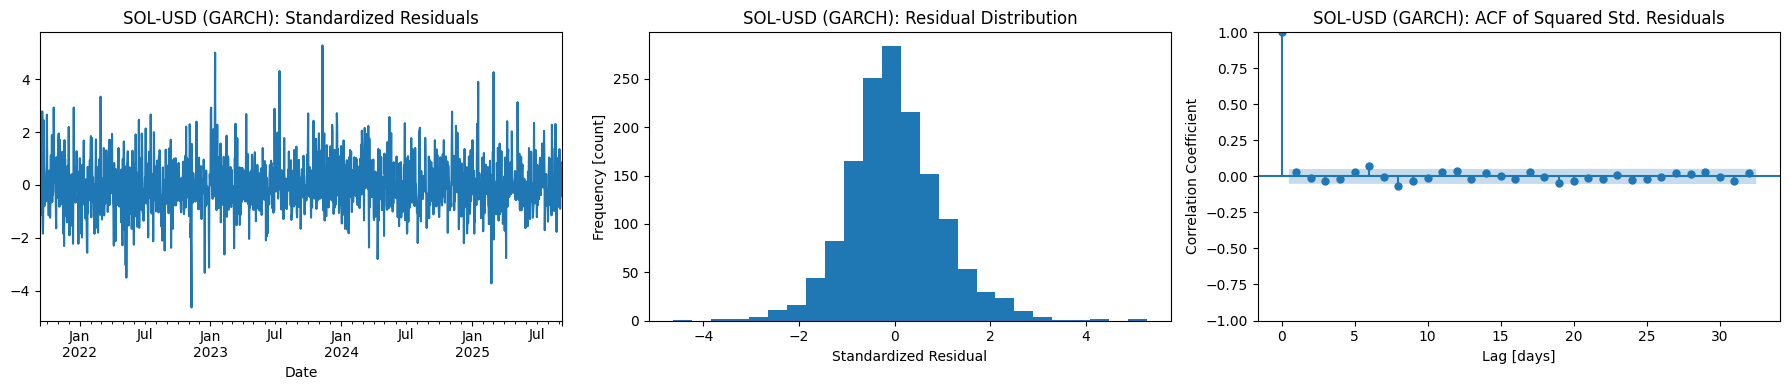

In [42]:
def plot_diagnostics(model_result, ticker, vol_model):
    """Plot residual diagnostics for one fitted model.

    Shows the standardised residuals over time, their distribution and the ACF
    of their squares.

    Args:
        model_result: Fitted ``ARCHModelResult``.
        ticker: Asset ticker used in the plot titles.
        vol_model: Specification name used in the plot titles.
    """
    std_resid = model_result.std_resid.dropna()

    fig, axes = plt.subplots(1, 3, figsize=(18, 4))

    std_resid.plot(ax=axes[0])
    axes[0].set_title(f"{ticker} ({vol_model}): Standardized Residuals")
    axes[0].set_xlabel("Date")

    axes[1].hist(std_resid, bins=25)
    axes[1].set_title(f"{ticker} ({vol_model}): Residual Distribution")
    axes[1].set_xlabel("Standardized Residual")
    axes[1].set_ylabel("Frequency [count]")

    plot_acf(std_resid ** 2, ax=axes[2])
    axes[2].set_title(f"{ticker} ({vol_model}): ACF of Squared Std. Residuals")
    axes[2].set_xlabel("Lag [days]")
    axes[2].set_ylabel("Correlation Coefficient")

    plt.tight_layout()
    plt.show()


# Diagnostics for each asset's best model by AIC
for ticker in all_tickers:
    best_vol_model = best_model_lookup[ticker]
    plot_diagnostics(fitted_models[ticker][best_vol_model].model, ticker, best_vol_model)

## Step 8: Walk Forward Validation
All three specifications are evaluated out of sample with walk forward forecasting. The out of sample results are then compared with the in sample ranking by AIC to answer the third research question.

**Walk forward forecasting.** At each step the model is refit using only the data available up to that day and produces a one day ahead volatility forecast. This mirrors real use and never looks at future data.

In [43]:
# Walk forward validation refits every model at each day of the test period, so the full run
# (6 assets, 3 specifications, whole test window) takes tens of minutes. MAX_TEST_DAYS caps
# the window for quick runs, and None uses the full test set
MAX_TEST_DAYS = None

In [49]:
def walk_forward_forecast(ticker, vol_model, p=1, q=1, max_test_days=None):
    """Run walk forward, one day ahead volatility forecasting for one asset.

    For each day of the test period the model is refit on all returns before that
    day and the next day's volatility is forecast. No future data is used.

    Args:
        ticker: Asset ticker.
        vol_model: One of "GARCH", "EGARCH" or "GJR-GARCH".
        p: Lag order of the symmetric innovations.
        q: Lag order of the lagged volatility.
        max_test_days: If set, only the most recent ``max_test_days`` of the test
            period are forecast. None uses the full test period.

    Returns:
        Series of predicted one day ahead volatility (standard deviation, not
        variance), indexed by date.
    """
    full_returns = returns_data[ticker]
    test_index = test_returns[ticker].index
    if max_test_days:
        test_index = test_index[-max_test_days:]
    test_size = len(test_index)

    predictions = []
    for i in range(test_size):
        window = full_returns.loc[:test_index[i]].iloc[:-1]

        if vol_model == "GARCH":
            spec = arch_model(window, p=p, q=q, vol="GARCH", rescale=False)
        elif vol_model == "EGARCH":
            spec = arch_model(window, p=p, o=1, q=q, vol="EGARCH", rescale=False)
        elif vol_model == "GJR-GARCH":
            spec = arch_model(window, p=p, o=1, q=q, vol="GARCH", rescale=False)

        fitted = spec.fit(disp=0)
        next_pred = fitted.forecast(horizon=1, reindex=False).variance.iloc[0, 0] ** 0.5
        predictions.append(next_pred)

    return pd.Series(predictions, index=test_index, name="predicted_volatility")

In [50]:
# Walk forward forecasts for every asset and specification
wfv_predictions = {}

for ticker in all_tickers:
    wfv_predictions[ticker] = {}
    for vol_model in vol_models:
        wfv_predictions[ticker][vol_model] = walk_forward_forecast(
            ticker=ticker, vol_model=vol_model, max_test_days=MAX_TEST_DAYS
        )
        print(f"{ticker} - {vol_model}: {wfv_predictions[ticker][vol_model].shape[0]} forecasts")

AAPL - GARCH: 251 forecasts
AAPL - EGARCH: 251 forecasts
AAPL - GJR-GARCH: 251 forecasts
JPM - GARCH: 251 forecasts
JPM - EGARCH: 251 forecasts
JPM - GJR-GARCH: 251 forecasts
XOM - GARCH: 251 forecasts
XOM - EGARCH: 251 forecasts
XOM - GJR-GARCH: 251 forecasts
BTC-USD - GARCH: 365 forecasts
BTC-USD - EGARCH: 365 forecasts
BTC-USD - GJR-GARCH: 365 forecasts
ETH-USD - GARCH: 365 forecasts
ETH-USD - EGARCH: 365 forecasts
ETH-USD - GJR-GARCH: 365 forecasts
SOL-USD - GARCH: 365 forecasts
SOL-USD - EGARCH: 365 forecasts
SOL-USD - GJR-GARCH: 365 forecasts


In [51]:
# Validate the forecast series
for ticker in all_tickers:
    for vol_model in vol_models:
        s = wfv_predictions[ticker][vol_model]
        assert isinstance(s, pd.Series)
        assert isinstance(s.index, pd.DatetimeIndex)
        assert s.isnull().sum() == 0

print("All walk-forward forecasts validated.")

All walk-forward forecasts validated.


**Evaluation metrics.** Two metrics score the forecasts. RMSE compares the forecast volatility with the absolute test return. QLIKE compares the forecast variance with the squared test return, and it is a standard loss in the volatility forecasting literature because it penalises under prediction of variance more heavily, which matters for risk management.

In [52]:
def qlike_loss(actual_sq_returns, predicted_variance):
    """QLIKE loss between squared returns and forecast variance.

    Lower is better. The loss penalises under prediction of variance more than
    over prediction.

    Args:
        actual_sq_returns: Squared returns used as the variance proxy.
        predicted_variance: Forecast variance.

    Returns:
        Mean QLIKE loss.
    """
    return np.mean(np.log(predicted_variance) + (actual_sq_returns / predicted_variance))


# Forecast accuracy per asset and specification
eval_rows = []
for ticker in all_tickers:
    asset_class = "equity" if ticker in equity_tickers else "crypto"
    actual = test_returns[ticker].loc[wfv_predictions[ticker]["GARCH"].index]
    actual_sq = actual ** 2

    for vol_model in vol_models:
        pred_vol = wfv_predictions[ticker][vol_model]
        pred_var = pred_vol ** 2

        rmse = np.sqrt(np.mean((actual.abs() - pred_vol) ** 2))
        qlike = qlike_loss(actual_sq, pred_var)

        eval_rows.append({
            "ticker": ticker,
            "asset_class": asset_class,
            "vol_model": vol_model,
            "rmse": rmse,
            "qlike": qlike,
        })

wfv_comparison_df = pd.DataFrame(eval_rows)
wfv_comparison_df.sort_values(["ticker", "qlike"])

,ticker,asset_class,vol_model,rmse,qlike
1,AAPL,equity,EGARCH,1.196970,1.880910
0,AAPL,equity,GARCH,1.214991,1.891409
2,AAPL,equity,GJR-GARCH,1.222453,1.902071
11,BTC-USD,crypto,GJR-GARCH,1.836589,2.581271
10,BTC-USD,crypto,EGARCH,1.837537,2.591422
9,BTC-USD,crypto,GARCH,1.839718,2.593451
13,ETH-USD,crypto,EGARCH,2.650731,3.392011
14,ETH-USD,crypto,GJR-GARCH,2.678742,3.426901
12,ETH-USD,crypto,GARCH,2.686989,3.450808
4,JPM,equity,EGARCH,1.017956,1.675493


In [53]:
# Best specification in sample (AIC) against best out of sample (QLIKE)
best_by_qlike = wfv_comparison_df.loc[wfv_comparison_df.groupby("ticker")["qlike"].idxmin()]

rq3_df = pd.DataFrame({
    "ticker": best_by_aic["ticker"].values,
    "asset_class": best_by_aic["asset_class"].values,
    "best_in_sample_aic": best_by_aic["vol_model"].values,
    "best_out_of_sample_qlike": best_by_qlike.set_index("ticker").loc[best_by_aic["ticker"], "vol_model"].values,
})
rq3_df["agrees"] = rq3_df["best_in_sample_aic"] == rq3_df["best_out_of_sample_qlike"]

rq3_df

,ticker,asset_class,best_in_sample_aic,best_out_of_sample_qlike,agrees
0,AAPL,equity,EGARCH,EGARCH,True
1,BTC-USD,crypto,EGARCH,GJR-GARCH,False
2,ETH-USD,crypto,GJR-GARCH,EGARCH,False
3,JPM,equity,EGARCH,EGARCH,True
4,SOL-USD,crypto,GARCH,GJR-GARCH,False
5,XOM,equity,GARCH,EGARCH,False


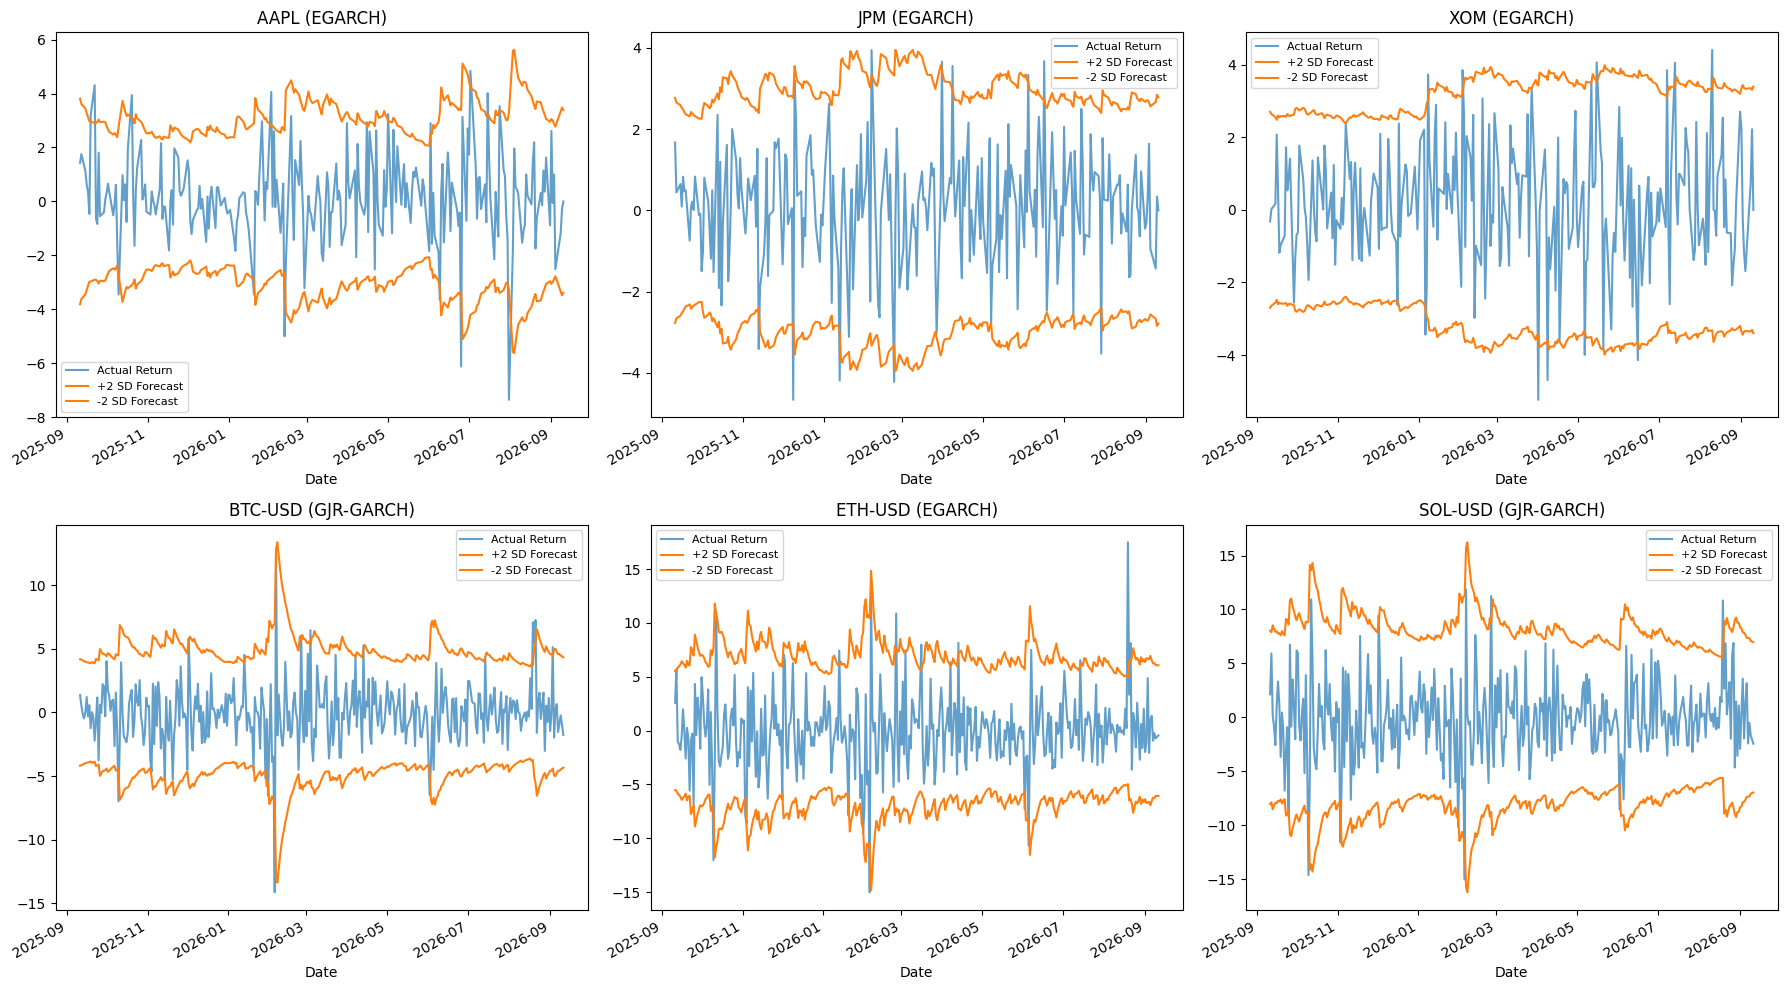

In [54]:
# Actual returns against the +/- 2 standard deviation band of the best out of sample forecast
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, ticker in zip(axes.flat, all_tickers):
    best_oos_model = best_by_qlike.set_index("ticker").loc[ticker, "vol_model"]
    pred_vol = wfv_predictions[ticker][best_oos_model]
    actual = test_returns[ticker].loc[pred_vol.index]

    actual.plot(ax=ax, label="Actual Return", alpha=0.7)
    (2 * pred_vol).plot(ax=ax, color="C1", label="+2 SD Forecast")
    (-2 * pred_vol).plot(ax=ax, color="C1", label="-2 SD Forecast")

    ax.set_title(f"{ticker} ({best_oos_model})")
    ax.set_xlabel("Date")
    ax.legend(fontsize=8)

plt.tight_layout()

## Step 9: Summary

**Findings from this run**

- **Volatility levels:** annualised volatility is about 24% to 28% for the equities (`JPM` 24.4%, `XOM` 26.7%, `AAPL` 28.0%) and much higher for the cryptocurrencies (`BTC-USD` 43.0%, `ETH-USD` 57.7%, `SOL-USD` 78.4%).
- **Research question 1, persistence:** there is no single answer. Mean persistence is higher for cryptocurrencies under GARCH (0.945 against 0.911) and GJR-GARCH (0.945 against 0.918), and lower under EGARCH (0.881 against 0.967). Persistence is defined differently for each specification, so the comparison is only meaningful within one.
- **Research question 2, asymmetry:** asymmetric models had the lowest AIC for `AAPL`, `JPM`, `BTC-USD` (EGARCH) and `ETH-USD` (GJR-GARCH), ahead of GARCH by 21 to 43 AIC points. Standard GARCH was best for `SOL-USD` and `XOM`, where GJR-GARCH was within 0.1 and 2 AIC points. The leverage effect is clearest in the equities `AAPL` and `JPM` (GJR gamma 0.145 and 0.223) and weaker in the cryptocurrencies (0.039 to 0.086). `XOM` shows none.
- **Research question 3, in sample against out of sample:** the best model by AIC was also the best by QLIKE for only 2 of 6 assets (`AAPL` and `JPM`). Standard GARCH was never the best out of sample, with EGARCH best for `AAPL`, `ETH-USD`, `JPM` and `XOM`, and GJR-GARCH best for `BTC-USD` and `SOL-USD`. RMSE picks the same model as QLIKE for 4 of 6 assets, and differs for `JPM` (GARCH) and `XOM` (GJR-GARCH).
- **Size of the differences:** the QLIKE gap between the best and second best model is 0.002 to 0.011 for five assets and 0.035 for `ETH-USD`. The differences are small and were not tested for statistical significance.

**Scope of the claims.** Results come from one chronological split, one day ahead forecasts and the data downloaded at run time, so they describe this sample and period and should not be read as general rules about equities and cryptocurrencies.